# Ajustar la correlación de activos a tasas de castigo: máxima verosimilitud, intervalos de perfil y prueba retrospectiva de cola

**Pregunta:** ¿Con qué fuerza se mueven juntos los incumplimientos de cada tipo de préstamo de Estados Unidos, cuánto pueden precisar esa correlación 22 años de tasas de castigo, y sobrevive el modelo ajustado a los años que siguen?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (la distribución de pérdidas de Vasicek de una cartera grande)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- escribir la verosimilitud de una serie de tasas de pérdida anuales bajo el modelo de un factor, y ajustar la PD y la correlación de activos por máxima verosimilitud con el motor;
- ajustar los mismos dos números por el método de momentos, y decir por qué las dos estimaciones de la correlación difieren;
- medir la incertidumbre de la correlación con un intervalo de verosimilitud de perfil y con un remuestreo paramétrico, y leer una curva de perfil;
- convertir cada año observado en un factor sistemático implícito, el índice del ciclo de crédito del ajuste;
- hacer una prueba retrospectiva de la distribución ajustada en los seis años posteriores a la ventana de ajuste, y decir qué concluye un validador para cada uno de los cinco tipos de préstamo de los bancos de Estados Unidos;
- comparar la correlación ajustada con la correlación regulatoria IRB de la clase de activos más cercana.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Nombres de las luces de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los cinco archivos por tipo de préstamo del caso C10, uno por columna de la tabla de castigos de la Reserva Federal `chgallsa` (https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm; dominio público, clase de licencia `mirror-allowed`): préstamos comerciales e industriales, inmobiliario comercial, inmobiliario residencial, tarjetas de crédito y otro consumo de todos los bancos comerciales de Estados Unidos, 1985 a 2012. La ventana de ajuste es 1985 a 2006 y la de evaluación 2007 a 2012. En cada archivo:

- `outputs.annual_rates` tiene una fila por año con la tasa de pérdida, o `null` y el motivo cuando la tabla de la Junta no tiene valor para ese tipo de préstamo; un año faltante se excluye y se cuenta, nunca se interpola;
- `outputs.fit` guarda los ajustes versionados, `outputs.profile_likelihood` la curva de perfil versionada, `outputs.backtest` la prueba retrospectiva versionado y `outputs.irb_reference` la comparación regulatoria.

La celda siguiente carga los cinco archivos y cuenta, para cada tipo de préstamo, los años que tienen tasa en cada ventana.

In [2]:
# Cargar los cinco artefactos y contar los años con tasa en cada ventana
NAMES = {
    "commercial-industrial": "Comerciales e industriales",
    "commercial-real-estate": "Inmobiliario comercial",
    "residential": "Inmobiliario residencial",
    "credit-cards": "Tarjetas de crédito",
    "other-consumer": "Otro consumo",
}
docs = {k: json.loads((ROOT / "data" / "derived" / "C10" / f"{k}.json").read_text(encoding="utf-8")) for k in NAMES}


def rates_of(key, window):
    """Tasas anuales de un tipo de préstamo en una ventana, NaN donde la Junta no tiene"""
    rows = docs[key]["outputs"]["annual_rates"]
    return np.array([np.nan if r["loss_rate"] is None else r["loss_rate"] for r in rows if r["window"] == window])


for key, label in NAMES.items():
    n_fit = int(np.isfinite(rates_of(key, "fit")).sum())
    n_eval = int(np.isfinite(rates_of(key, "evaluation")).sum())
    print(f"{label:28s} años de ajuste: {n_fit:3d} | años de evaluación: {n_eval:3d}")

Comerciales e industriales   años de ajuste:  22 | años de evaluación:   6
Inmobiliario comercial       años de ajuste:  16 | años de evaluación:   6
Inmobiliario residencial     años de ajuste:  16 | años de evaluación:   6
Tarjetas de crédito          años de ajuste:  22 | años de evaluación:   6
Otro consumo                 años de ajuste:  22 | años de evaluación:   6


## Método

### Paso 1: la verosimilitud y el ajuste por máxima verosimilitud

Bajo el modelo de un factor la tasa de pérdida anual $x_t$ de una cartera muy grande es $p(Z_t)$ con $Z_t$ normal estándar, así que $x_t$ tiene la densidad de la cartera grande (la derivada de la función de distribución del cuaderno 01; Vasicek, 2002, y Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8):

$$f(x;\mathrm{PD},\rho) = \sqrt{\frac{1-\rho}{\rho}}\; \exp\!\left(\tfrac12\,\Phi^{-1}(x)^2 - \frac{\left(\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(\mathrm{PD})\right)^2}{2\rho}\right)$$

Tomando los años como independientes, la log-verosimilitud de una serie es $\ell(\mathrm{PD},\rho)=\sum_t \ln f(x_t;\mathrm{PD},\rho)$, y la estimación es el par que la maximiza. `log_likelihood` del motor la evalúa y `fit_ml` la maximiza (una búsqueda Nelder-Mead en escala logit desde un inicio fijo, así que el resultado es determinista). La celda siguiente toma las 22 tasas de la ventana de ajuste de los préstamos comerciales e industriales, las ajusta y recorre la log-verosimilitud en la correlación con la PD ajustada.

In [3]:
# Ajustar por máxima verosimilitud y recorrer la verosimilitud en la correlación
from riskvalidation.portfolio.asrf_fit import fit_ml, log_likelihood

ci = docs["commercial-industrial"]["outputs"]
rows = ci["annual_rates"]
fit_rates = rates_of("commercial-industrial", "fit")
eval_rates = rates_of("commercial-industrial", "evaluation")
eval_years = [r["year"] for r in rows if r["window"] == "evaluation"]

est = fit_ml(fit_rates)
print("años usados:", est.n_years, "| faltantes:", est.n_missing, "| convergió:", "sí" if est.converged else "no")
print("PD:", round(est.pd, 6), "| rho:", round(est.rho, 6))
print("log-verosimilitud:", round(est.log_likelihood, 4))

rho_scan = np.linspace(0.01, 0.30, 59)
ll_scan = np.array([log_likelihood(fit_rates, est.pd, r) for r in rho_scan])
print("mejor rho en la grilla:", round(float(rho_scan[ll_scan.argmax()]), 3))

años usados: 22 | faltantes: 0 | convergió: sí
PD: 0.009105 | rho: 0.063677
log-verosimilitud: 84.8232
mejor rho en la grilla: 0.065


La log-verosimilitud es una curva en $\rho$ con un solo pico, y el pico es la estimación. Su ancho es la información que los 22 años tienen sobre la correlación: una cima plana significa que los datos apenas distinguen valores vecinos. La celda siguiente la dibuja.

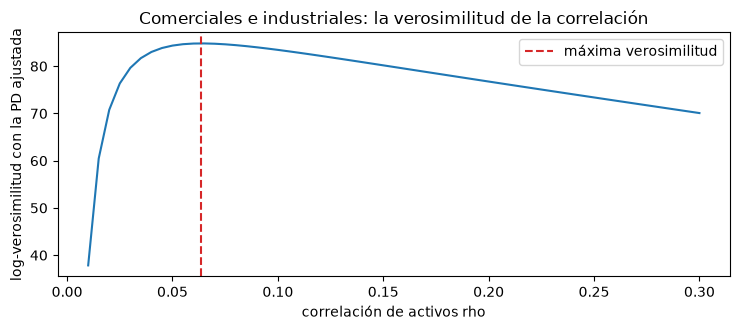

In [4]:
# Dibujar la log-verosimilitud en la correlación con la PD ajustada
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(rho_scan, ll_scan, color="tab:blue")
ax.axvline(est.rho, color="tab:red", linestyle="--", label="máxima verosimilitud")
ax.set_xlabel("correlación de activos rho")
ax.set_ylabel("log-verosimilitud con la PD ajustada")
ax.set_title("Comerciales e industriales: la verosimilitud de la correlación")
ax.legend()
fig.tight_layout()
plt.show()

La curva tiene un solo pico claro y el pico es la estimación, una correlación cercana a 0,064 con la PD ajustada. A la izquierda la verosimilitud cae rápido, porque una correlación cercana a cero no puede explicar años tan distintos como 1985 y 2009; a la derecha cae mucho más despacio, así que los datos casi no distinguen una correlación de 0,10 de una de 0,12. Esa asimetría es la primera señal de que el intervalo de los pasos siguientes será más largo a la derecha que a la izquierda. La figura mantiene fija la PD, así que muestra la correlación sola y no la incertidumbre conjunta de los dos parámetros.

### Paso 2: el método de momentos, una alternativa que discrepa

Un estimador más simple iguala dos momentos. La media de la tasa de pérdida es la PD, y el segundo momento de la fracción de incumplimientos de la cartera grande es la probabilidad de que dos deudores caigan juntos en incumplimiento, $E[p(Z)^2]$ (el resultado del dossier, dossier 04 C.4). La estimación es la PD igual a la media de las tasas y la correlación que hace que $E[p(Z)^2]$ sea igual a la media de las tasas al cuadrado. `fit_moments` del motor lo resuelve por búsqueda de raíz, y lanza un error en lugar de devolver cero cuando las tasas no muestran dispersión en exceso. La celda siguiente ajusta ambos estimadores y evalúa la verosimilitud en cada uno, para compararlos en la misma escala.

In [5]:
# Ajustar por momentos y evaluar la verosimilitud en ambas estimaciones
from riskvalidation.portfolio.asrf_fit import fit_moments

mom = fit_moments(fit_rates)
print("momentos: PD", round(mom.pd, 6), "| rho", round(mom.rho, 6))
print("media de las tasas:", round(float(fit_rates.mean()), 6))
print(f"{'':22s} rho      log-verosimilitud")
print(f"{'máxima verosimilitud':22s} {est.rho:.4f}   {est.log_likelihood:.4f}")
print(f"{'momentos':22s} {mom.rho:.4f}   {log_likelihood(fit_rates, mom.pd, mom.rho):.4f}")

momentos: PD 0.008972 | rho 0.042594
media de las tasas: 0.008972
                       rho      log-verosimilitud
máxima verosimilitud   0.0637   84.8232
momentos               0.0426   83.5628


### Paso 3: la verosimilitud de perfil y su intervalo

Una estimación puntual de $\rho$ no dice nada de cuán bien la fijan 22 años. La **log-verosimilitud de perfil** fija $\rho$ en cada valor de una grilla, maximiza sobre la PD y registra el máximo: $\ell_p(\rho)=\max_{\mathrm{PD}}\ell(\mathrm{PD},\rho)$. El intervalo de razón de verosimilitud conserva los valores de $\rho$ cuyo perfil está a menos de $\chi^2_{1;0{,}95}/2 = 1{,}9207$ de la cima. `profile_likelihood` del motor evalúa la curva en una grilla y `profile_interval` encuentra los extremos. La celda siguiente evalúa el perfil en una grilla de 42 correlaciones y halla el intervalo de 95% de la correlación y de la PD.

In [6]:
# Evaluar la log-verosimilitud de perfil en una grilla y hallar el intervalo de razón de verosimilitud
from scipy import stats

from riskvalidation.portfolio.asrf_fit import profile_interval, profile_likelihood

grid = np.linspace(0.015, 0.25, 42)
ll_profile, pd_at_rho = profile_likelihood(fit_rates, grid)
drop = stats.chi2.ppf(0.95, 1) / 2
print("caída bajo la cima para 95%:", round(float(drop), 4))

interval = profile_interval(fit_rates, 0.95)
print("rho intervalo de 95%:", tuple(round(v, 4) for v in interval["rho"]))
print("PD intervalo de 95%:", tuple(round(v, 5) for v in interval["pd"]))

caída bajo la cima para 95%: 1.9207
rho intervalo de 95%: (0.0382, 0.1158)
PD intervalo de 95%: (0.0068, 0.01297)


La imagen muestra por qué el intervalo es asimétrico: el perfil cae despacio hacia la derecha, así que las correlaciones altas siguen siendo plausibles mucho después de que las bajas quedan excluidas. La celda siguiente dibuja el perfil, el corte, el intervalo y la estimación de momentos.

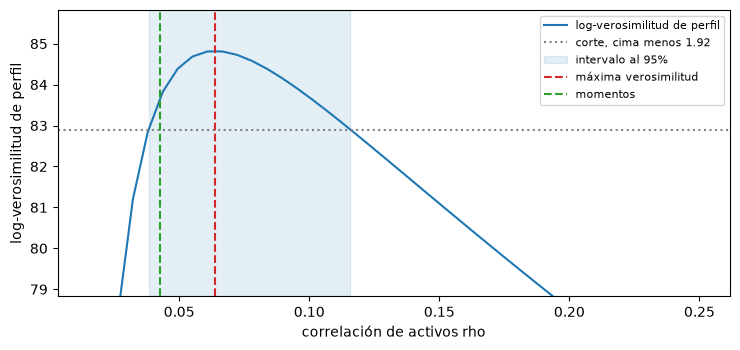

In [7]:
# Dibujar la log-verosimilitud de perfil con su corte, el intervalo y la estimación de momentos
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(grid, ll_profile, color="tab:blue", label="log-verosimilitud de perfil")
ax.axhline(est.log_likelihood - drop, color="gray", linestyle=":", label="corte, cima menos 1.92")
ax.axvspan(*interval["rho"], color="tab:blue", alpha=0.12, label="intervalo al 95%")
ax.axvline(est.rho, color="tab:red", linestyle="--", label="máxima verosimilitud")
ax.axvline(mom.rho, color="tab:green", linestyle="--", label="momentos")
ax.set_xlabel("correlación de activos rho")
ax.set_ylabel("log-verosimilitud de perfil")
ax.set_ylim(est.log_likelihood - 6, est.log_likelihood + 1)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

El perfil hace comparables los dos estimadores en un solo eje. La banda azul es el intervalo de 95%, la línea roja la correlación de máxima verosimilitud y la línea verde la estimación de momentos, que cae dentro de la banda pero en su hombro inferior, donde el perfil ya está bien por debajo de la cima. La banda no está centrada en la línea roja: llega mucho más a la derecha, de modo que los datos admiten una correlación de 0,11 o más con mucha más facilidad que una menor de 0,04. Una cifra de capital que crece con la correlación tiene entonces más espacio para quedar baja que alta. El perfil no muestra nada de la dependencia entre años consecutivos, que revelan los factores del paso 5.

### Paso 4: un remuestreo paramétrico para la estimación de momentos

El método de momentos no tiene verosimilitud que perfilar, así que su incertidumbre viene de un **remuestreo paramétrico**: tomar el $(\mathrm{PD},\rho)$ ajustado, sortear 22 factores sistemáticos nuevos $z_t \sim N(0,1)$, convertir cada uno en una tasa de pérdida $p(z_t)$, reajustar y repetir. Los percentiles 2,5% y 97,5% de los valores reajustados son el intervalo. `bootstrap_interval` del motor lo hace con un generador con semilla, así que es reproducible; un reajuste que falla se descarta y se cuenta. La celda siguiente corre 500 reajustes con semilla e imprime el intervalo de la correlación y de la PD.

In [8]:
# Correr el remuestreo paramétrico con semilla de la estimación de momentos
from riskvalidation.portfolio.asrf_fit import bootstrap_interval

boot = bootstrap_interval(fit_rates, "moments", 500, 4007, 0.95)
print("reajustes:", boot.n_boot, "| descartados:", boot.n_dropped)
print("rho intervalo por remuestreo:", tuple(round(v, 4) for v in boot["rho"]))
print("PD intervalo por remuestreo:", tuple(round(v, 5) for v in boot["pd"]))
inside = interval["rho"][0] <= mom.rho <= interval["rho"][1]
print("estimación de momentos dentro del intervalo de verosimilitud:", "sí" if inside else "no")

reajustes: 500 | descartados: 0
rho intervalo por remuestreo: (0.0189, 0.0755)
PD intervalo por remuestreo: (0.00727, 0.01136)
estimación de momentos dentro del intervalo de verosimilitud: sí


### Paso 5: el factor sistemático implícito de cada año

Dado el $(\mathrm{PD},\rho)$ ajustado, cada tasa de pérdida anual implica el valor del factor sistemático que la habría producido, la inversa de la PD condicional del cuaderno 01:

$$\hat z_t = \frac{\Phi^{-1}(\mathrm{PD}) - \sqrt{1-\rho}\,\Phi^{-1}(x_t)}{\sqrt{\rho}}$$

La serie $\hat z_t$ es el índice del ciclo de crédito del ajuste: negativa en los años malos, positiva en los buenos (Belkin, Suchower y Forest, 1998; aquí una derivación del modelo, no una ecuación citada). Si el modelo fuera correcto, los $\hat z_t$ se verían como sorteos de una normal estándar. `implied_factors` del motor calcula toda la serie y deja NaN donde falta un año. La celda siguiente la calcula para los 28 años e imprime su media, su dispersión, su año más bajo y su autocorrelación de rezago 1.

In [9]:
# Calcular el factor implícito de los 28 años y resumirlo
from riskvalidation.portfolio.asrf_fit import implied_factors

all_rates = np.array([np.nan if r["loss_rate"] is None else r["loss_rate"] for r in rows])
all_years = np.array([r["year"] for r in rows])
in_fit = np.array([r["window"] == "fit" for r in rows])
z_hat = implied_factors(all_rates, est.pd, est.rho)

print("media y desviación estándar de los factores de la ventana de ajuste:")
print("   ", round(float(z_hat[in_fit].mean()), 3), round(float(z_hat[in_fit].std(ddof=1)), 3))
print("factor más bajo:", int(all_years[np.nanargmin(z_hat)]), round(float(np.nanmin(z_hat)), 3))
print("autocorrelación de rezago 1 de los 28 factores:", round(float(np.corrcoef(z_hat[:-1], z_hat[1:])[0, 1]), 3))

media y desviación estándar de los factores de la ventana de ajuste:
    -0.0 1.024
factor más bajo: 2009 -1.708
autocorrelación de rezago 1 de los 28 factores: 0.761


La celda siguiente dibuja los 28 factores implícitos como barras, coloreadas por ventana.

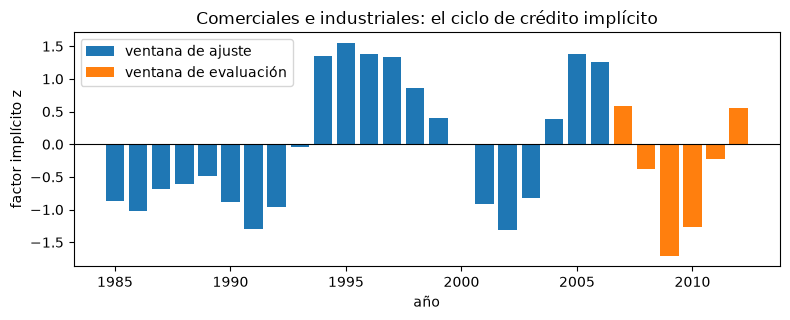

In [10]:
# Dibujar los factores implícitos con las dos ventanas marcadas
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(all_years[in_fit], z_hat[in_fit], color="tab:blue", label="ventana de ajuste")
ax.bar(all_years[~in_fit], z_hat[~in_fit], color="tab:orange", label="ventana de evaluación")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("año")
ax.set_ylabel("factor implícito z")
ax.set_title("Comerciales e industriales: el ciclo de crédito implícito")
ax.legend()
fig.tight_layout()
plt.show()

Las barras son el ciclo de crédito que el modelo lee en las tasas de pérdida. Las rachas negativas son tiempos malos y vienen en bloques: 1985 a 1992, 2001 a 2003 y 2008 a 2011, con 2009 el más bajo. Las rachas positivas llenan 1994 a 1998 y 2004 a 2007. Si los factores fueran sorteos independientes las barras cambiarían de signo al azar, y claramente no lo hacen, lo que cuantifica la autocorrelación de rezago 1 de arriba. La verosimilitud trata los años como independientes, así que su intervalo es condicional a una propiedad que los datos contradicen; la figura no puede decir cuánto más estrecho de lo debido es el intervalo, solo que lo es.

### Paso 6: una prueba retrospectiva de cola en los seis años posteriores al ajuste

Una distribución ajustada hace una predicción: en $n$ años futuros, el número de años sobre su cuantil $q$ es Binomial$(n, 1-q)$. `tail_backtest` del motor cuenta los años de la ventana de evaluación sobre los cuantiles ajustados al 95%, 99% y 99,9% e informa la cola binomial superior $P(X \ge \text{observado})$ como su valor p, al nivel primario de 99%; es una puerta interna de Contraste con la luz verde desde un valor p de 0,05 y roja bajo 0,01, no un umbral regulatorio. Con seis años la prueba tiene poca potencia, así que los conteos se muestran junto al valor p. La celda siguiente la corre con los préstamos comerciales e industriales e imprime los conteos en los tres niveles.

In [11]:
# Contrastar el ajuste comercial e industrial con 2007 a 2012
from riskvalidation.validation.portfolio import tail_backtest

levels = (0.95, 0.99, 0.999)
result = tail_backtest(eval_rates, est.pd, est.rho, levels=levels, primary_level=0.99, model_id="m-lhp")
print("luz:", LIGHTS[result.light.value], "| p-value:", round(result.p_value, 6))
print("observados al 99%:", int(result.statistic), "| esperados:", round(result.metric, 4))
print(f"{'q':>6s} {'cuantil ajustado':>20s} {'esperados':>10s} {'observados':>10s} {'p':>8s}")
for row in result.extras["levels"]:
    head = f"{row['level']:6.3f} {row['fitted_quantile']:20.5f}"
    print(head, f"{row['expected']:10.3f} {row['observed']:10d} {row['p_value']:8.4f}")

luz: verde | p-value: 1.0
observados al 99%: 0 | esperados: 0.06
     q     cuantil ajustado  esperados observados        p
 0.950              0.02214      0.300          1   0.2649
 0.990              0.03335      0.060          0   1.0000
 0.999              0.05109      0.006          0   1.0000


La celda siguiente dibuja los seis años de evaluación frente a los cuantiles ajustados de 95%, 99% y 99,9%.

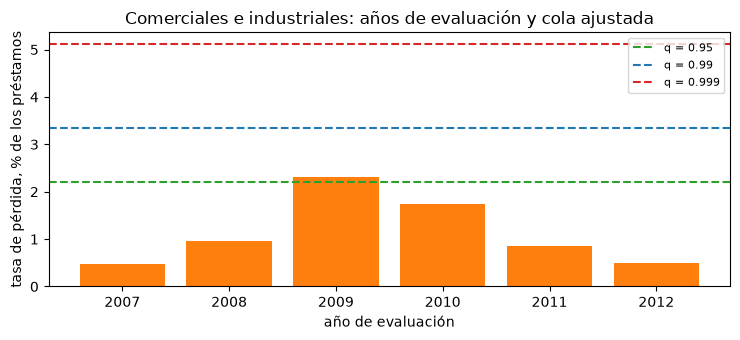

In [12]:
# Dibujar los años de evaluación frente a los cuantiles ajustados
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar([str(y) for y in eval_years], 100 * eval_rates, color="tab:orange")
for row, color in zip(result.extras["levels"], ("tab:green", "tab:blue", "tab:red")):
    ax.axhline(100 * row["fitted_quantile"], color=color, linestyle="--", label=f"q = {row['level']}")
ax.set_xlabel("año de evaluación")
ax.set_ylabel("tasa de pérdida, % de los préstamos")
ax.set_title("Comerciales e industriales: años de evaluación y cola ajustada")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Solo 2009 cruza una línea punteada, y solo la del 95%: el peor año de toda la serie queda bajo el cuantil 99% ajustado. Las barras de 2007, 2008, 2011 y 2012 quedan bajo el 1% de los préstamos, muy por debajo de todas las líneas, y 2010 con 1,74% también queda bajo la línea del 95%. Es lo que el modelo predice para una ventana de seis años, y por eso la prueba sale verde, pero la prueba tiene poca potencia: necesita dos años sobre la línea del 99% para ponerse roja, y un modelo con un cuantil demasiado bajo igual pasaría si los seis años resultaran benignos. La figura muestra solo los préstamos comerciales e industriales; los tipos minoristas de las celdas siguientes se comportan distinto.

La misma cadena de pasos corre para cada tipo de préstamo. La celda siguiente ajusta la ventana de ajuste de cada tipo, mide el intervalo de perfil, hace la prueba retrospectiva de la ventana de evaluación y recalcula la correlación regulatoria IRB de la clase de activos más cercana con `capital_requirement` del motor (Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm; la clase es la clase regulatoria más cercana, no una afirmación de que la serie de la Junta sea esa clase). Imprime una fila por tipo de préstamo: la correlación ajustada y su intervalo, la correlación IRB, los años sobre el cuantil 99% ajustado y la luz.

In [13]:
# Ajustar, perfilar y contrastar los cinco tipos frente a la correlación IRB
from riskvalidation.regulatory.irb import capital_requirement

summary = {}
for key in NAMES:
    fit_k = rates_of(key, "fit")
    fitted = fit_ml(fit_k)
    band = profile_interval(fit_k, 0.95)["rho"]
    evaluation = rates_of(key, "evaluation")
    test = tail_backtest(evaluation, fitted.pd, fitted.rho, levels=levels, primary_level=0.99, model_id="m-lhp")
    asset_class = docs[key]["outputs"]["irb_reference"]["asset_class"]
    extra = {} if asset_class in ("residential_mortgage", "qrre", "other_retail") else {"maturity": 2.5}
    irb = capital_requirement(asset_class, fitted.pd, 0.45, regime="basel3", **extra)
    summary[key] = (fitted, band, test, irb)

print(f"{'tipo de préstamo':26s} {'años':>5s} {'rho':>7s} {'rho IRB':>8s} {'>q99':>5s} {'p':>9s} luz")
for key, label in NAMES.items():
    fitted, band, test, irb = summary[key]
    head = f"{label:26s} {fitted.n_years:5d} {fitted.rho:7.4f} {irb.correlation:8.4f}"
    print(head, f"{int(test.statistic):5d} {test.p_value:9.2e}", LIGHTS[test.light.value])

tipo de préstamo            años     rho  rho IRB  >q99         p luz
Comerciales e industriales    22  0.0637   0.1961     0  1.00e+00 verde
Inmobiliario comercial        16  0.2384   0.2647     0  1.00e+00 verde
Inmobiliario residencial      16  0.0129   0.1500     5  5.95e-10 rojo
Tarjetas de crédito           22  0.0127   0.0400     2  1.46e-03 rojo
Otro consumo                  22  0.0109   0.1224     3  1.96e-05 rojo


La celda siguiente dibuja, para cada tipo de préstamo, la correlación ajustada con su intervalo de 95% y la correlación regulatoria IRB de la clase de activos más cercana.

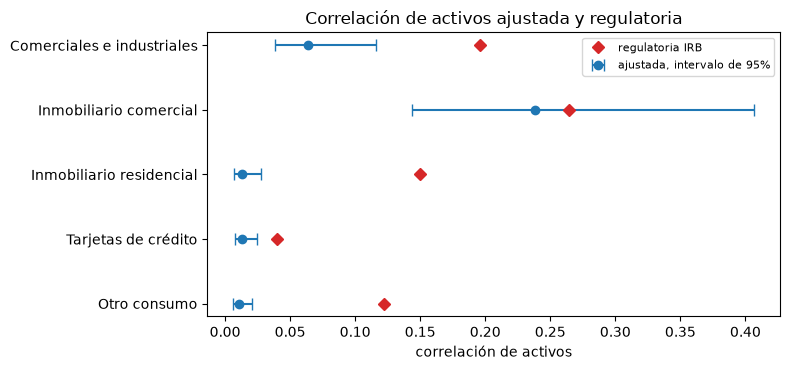

In [14]:
# Dibujar la correlación ajustada con su intervalo junto a la correlación IRB
rho_fit = np.array([summary[k][0].rho for k in NAMES])
low = rho_fit - np.array([summary[k][1][0] for k in NAMES])
high = np.array([summary[k][1][1] for k in NAMES]) - rho_fit
rho_irb = np.array([summary[k][3].correlation for k in NAMES])
position = np.arange(len(NAMES))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(rho_fit, position, xerr=[low, high], fmt="o", color="tab:blue", capsize=4,
            label="ajustada, intervalo de 95%")
ax.plot(rho_irb, position, "D", color="tab:red", label="regulatoria IRB")
ax.set_yticks(position, list(NAMES.values()))
ax.invert_yaxis()
ax.set_xlabel("correlación de activos")
ax.set_title("Correlación de activos ajustada y regulatoria")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los puntos azules con sus barras son lo que respalda cada serie de tasas de pérdida anuales; los rombos rojos son los valores supervisores. Cuatro de los cinco rombos quedan muy a la derecha de toda la barra azul, lo que dice que las correlaciones ajustadas no están solo un poco bajo las regulatorias sino fuera del rango que permiten los datos. El inmobiliario comercial es la excepción: su barra es ancha, de 0,14 a 0,41, y el valor regulatorio cae dentro. Los anchos difieren porque la serie inmobiliaria tiene solo 16 años usables y un ciclo mucho más fuerte. La comparación mide una brecha, no su causa, porque los valores IRB son calibraciones para grandes bancos activos internacionalmente, no estimaciones de esta tabla.

La fórmula regulatoria y el ajuste responden preguntas distintas, así que comparamos su capital y no solo sus correlaciones. El bloque versionado `irb_reference` guarda, por tipo de préstamo, el capital de la cartera grande al 99,9% con la correlación ajustada y el capital IRB $K$, ambos con la misma PD, una LGD de 45% y el mismo ajuste por vencimiento; su razón es el número versionado que cita la vista ejecutiva. La celda siguiente recalcula el capital ajustado con la correlación ajustada y el ajuste por vencimiento IRB, y lo divide por el capital IRB.

In [15]:
# Calcular el capital ajustado al 99,9% y su razón al capital IRB
from riskvalidation.engines.vasicek import lhp_quantile

ratios = {}
print(f"{'tipo de préstamo':26s} {'capital ajustado':>18s} {'K IRB':>8s} {'razón':>8s}")
for key, label in NAMES.items():
    fitted, _, _, irb = summary[key]
    tail = float(lhp_quantile(0.999, fitted.pd, fitted.rho)) - fitted.pd
    capital = 0.45 * tail * (irb.maturity_adjustment or 1.0)
    ratios[key] = capital / float(irb.k)
    print(f"{label:26s} {capital:18.5f} {float(irb.k):8.5f} {ratios[key]:8.3f}")

tipo de préstamo             capital ajustado    K IRB    razón
Comerciales e industriales            0.02397  0.07137    0.336
Inmobiliario comercial                0.05870  0.06679    0.879
Inmobiliario residencial              0.00115  0.01102    0.104
Tarjetas de crédito                   0.01835  0.03917    0.468
Otro consumo                          0.00529  0.03622    0.146


La celda siguiente dibuja la razón del capital ajustado al capital IRB, una barra por tipo de préstamo, con la línea de capital igual en 1.

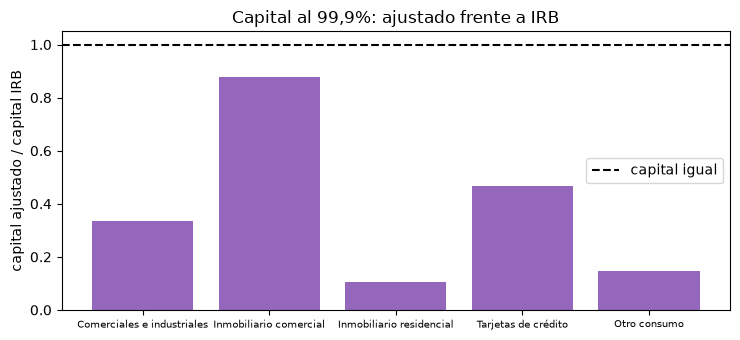

In [16]:
# Dibujar la razón del capital ajustado al capital IRB
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(list(NAMES.values()), [ratios[k] for k in NAMES], color="tab:purple")
ax.axhline(1.0, color="black", linestyle="--", label="capital igual")
ax.set_ylabel("capital ajustado / capital IRB")
ax.set_title("Capital al 99,9%: ajustado frente a IRB")
ax.tick_params(axis="x", labelsize=7)
ax.legend()
fig.tight_layout()
plt.show()

Todas las barras están bajo la línea punteada, así que con la misma PD, una LGD de 45% y el mismo ajuste por vencimiento la correlación ajustada pediría menos capital que la fórmula IRB para los cinco tipos de préstamo. La diferencia es de un factor tres en los préstamos comerciales e industriales y de casi diez en el inmobiliario residencial, mientras el inmobiliario comercial queda cerca de la paridad. La razón mezcla dos efectos, una correlación menor y la forma del cuantil de pérdida, y las barras no dicen si la fórmula supervisora es demasiado conservadora o la ventana de ajuste benigna demasiado amable: la prueba retrospectiva de los tipos minoristas apunta a la segunda lectura para ellos.

## Resultados

**Respuesta:** los incumplimientos de los préstamos comerciales e industriales se mueven juntos con una correlación de activos de 0,0637 y una PD de 0,91%, pero 22 años de tasas solo fijan la correlación dentro de un intervalo de 95% de 0,0382 a 0,1158; el ajuste pasa la prueba de 2007 a 2012 para ese tipo de préstamo (ningún año sobre el cuantil 99%) y la falla para los tres tipos minoristas, y su capital es un tercio del capital IRB (razón 0,336).

- **El ajuste de máxima verosimilitud.** Con los 22 años de la ventana de ajuste de los préstamos comerciales e industriales, la máxima verosimilitud da una PD de 0,91% y una correlación de 0,0637, con una log-verosimilitud de 84,82 y una búsqueda convergida. La log-verosimilitud en la correlación tiene un solo pico, más empinado a la izquierda que a la derecha.
- **Los dos estimadores discrepan, y la verosimilitud dice cuál ajusta mejor.** El método de momentos da una correlación de 0,0426, frente a 0,0637 de la máxima verosimilitud; la log-verosimilitud es 83,56 en la estimación de momentos y 84,82 en el máximo. La estimación de momentos queda dentro del intervalo de verosimilitud, así que los datos no la excluyen, pero es la menos eficiente de las dos.
- **Veintidós años fijan la correlación solo de forma holgada.** El intervalo de razón de verosimilitud es 0,0382 a 0,1158, un rango de un factor tres, y es asimétrico: el perfil cae despacio hacia la derecha. El intervalo por remuestreo de la estimación de momentos, 0,0189 a 0,0755, sale de 500 reajustes con semilla y ninguno se descartó. Toda cifra de capital que dependa de la correlación hereda este rango.
- **El ciclo de crédito es persistente, y el modelo supone que no lo es.** Los factores implícitos de la ventana de ajuste tienen media 0,0 y desviación estándar 1,02, como tendría una normal estándar, y el más bajo es 2009 con -1,71. Pero la autocorrelación de rezago 1 de los 28 factores es 0,76: un año malo tiende a ser seguido por otro. La verosimilitud trata los años como independientes, así que su intervalo es condicional a ese supuesto y probablemente optimista.
- **La prueba retrospectiva separa los tipos de préstamo.** Para los préstamos comerciales e industriales ningún año de evaluación supera el cuantil 99% ajustado (0,06 esperados) y uno supera el cuantil 95% (2009, 0,30 esperados): verde, p = 1,0. El inmobiliario comercial también es verde. El inmobiliario residencial tiene 5 de 6 años sobre el cuantil 99% (p = 6e-10), las tarjetas de crédito 2 de 6 (p = 0,0015) y otro consumo 3 de 6 (p = 2e-5): todos rojos. Los tres tipos minoristas se ajustaron en una ventana sin la crisis de 2007 a 2009 (el residencial además tiene solo 16 años usables, pues la tabla de la Junta no tiene valor antes de 1991), y la ventana de evaluación es esa crisis. La prueba no dice que el modelo de un factor sea incorrecto; dice que un ajuste en una ventana benigna subestima la cola que enfrentará después.
- **La correlación ajustada queda bajo la regulatoria en los cinco tipos, y muy bajo en cuatro.** Comerciales e industriales: 0,0637 frente a 0,1961 del IRB; residencial: 0,0129 frente a 0,15; tarjetas de crédito: 0,0127 frente a 0,04; otro consumo: 0,0109 frente a 0,1224. El inmobiliario comercial es el cercano, 0,2384 frente a 0,2647. Las razones de capital ajustado a IRB son 0,336, 0,104, 0,468, 0,146 y 0,879. La comparación mide el tamaño de la brecha y no su causa: las correlaciones IRB son calibraciones supervisoras, y nada aquí dice que estén equivocadas.

Lo que este cuaderno no muestra: cuán bien recupera cada estimador una correlación conocida (el estudio de tamaño y potencia, cuadernos 06 y 08), qué implica la correlación para una cartera finita (cuadernos 03 a 05), o cómo cambia el intervalo cuando los años son dependientes.

## Resumen

- La verosimilitud de las tasas de pérdida anuales bajo el modelo de un factor es la suma de las log-densidades de la cartera grande; `fit_ml` la maximiza y `fit_moments` iguala los dos primeros momentos, y los dos difieren.
- La incertidumbre de la correlación es un intervalo de verosimilitud de perfil (`profile_likelihood`, `profile_interval`) o un remuestreo paramétrico con semilla (`bootstrap_interval`); con 22 años abarca un factor de tres.
- `implied_factors` convierte cada año en el índice del ciclo de crédito del ajuste; su fuerte autocorrelación dice que el supuesto de años independientes es optimista.
- `tail_backtest` cuenta años de evaluación sobre los cuantiles ajustados frente a una binomial; aprueba los préstamos comerciales y reprueba los tipos minoristas ajustados sobre una ventana benigna.
- La correlación ajustada queda bajo la IRB en los cinco tipos, y la razón de capital frente a IRB es el número que hay que leer, con el intervalo al lado.

**Qué probar a continuación.** Cambia la ventana de ajuste a 1985 a 2009 para los tipos minoristas y repite la prueba retrospectiva en 2010 a 2012. Luego abre el cuaderno 03, donde la correlación ajustada gobierna un Monte Carlo de una cartera finita.

## Referencias

- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Belkin, B., Suchower, S. y Forest, L. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, as cited by the engine's `engines.vasicek` module.
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections C.4 (the Vasicek model and the moment equation) and H.1 (the loss measures).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.